# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1.   Mariajose Sanabria Orjuela
 2.   
 3.    
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [6]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

<Axes: title={'center': 'Top 5 productos por ingresos'}, ylabel='producto'>

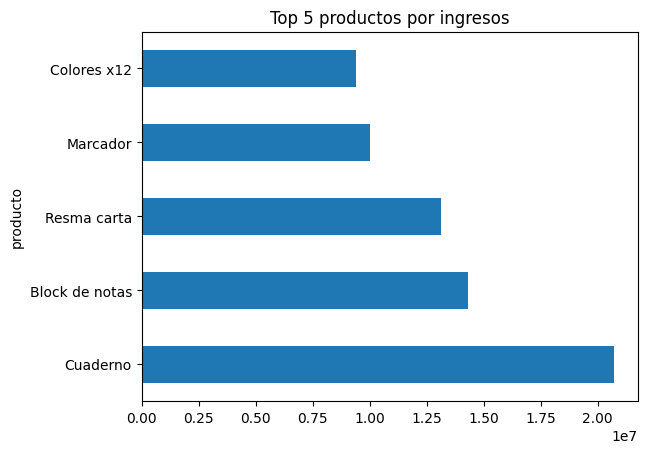

In [7]:
# Ejercicio 1
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
top_productos.plot.barh(title="Top 5 productos por ingresos")


In [ ]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

<Axes: title={'center': 'Ingresos mensuales: Bogotá vs Medellín'}, xlabel='mes'>

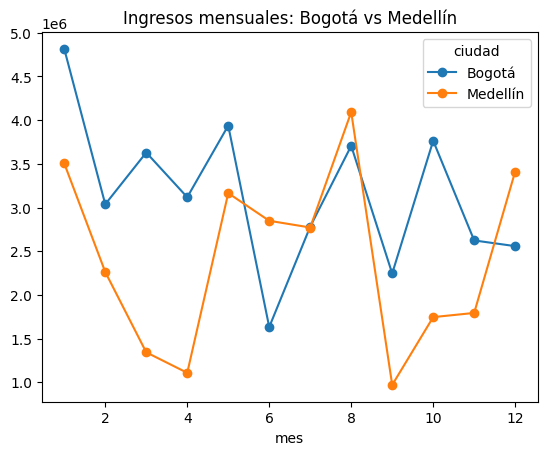

In [8]:
# Ejercicio 2
ing_mes_ciudad = df[df["ciudad"].isin(["Bogotá", "Medellín"])].pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum"
)
ing_mes_ciudad.plot.line(marker="o", title="Ingresos mensuales: Bogotá vs Medellín")

In [ ]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

<Axes: title={'center': 'Ingresos por canal'}, ylabel='total'>

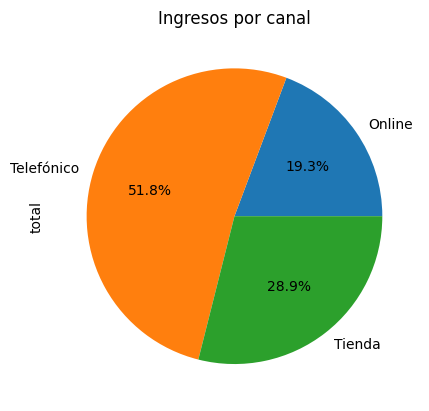

In [9]:
# Ejercicio 3
ing_canal = df.groupby("canal")["total"].sum()
ing_canal.plot.pie(autopct="%.1f%%", title="Ingresos por canal")

In [ ]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

<Axes: title={'center': 'Categorías por segmento (%)'}, xlabel='segmento'>

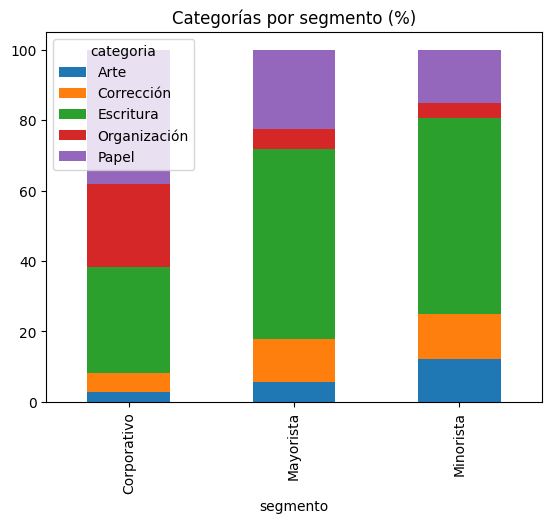

In [10]:
# Ejercicio 4
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(stacked=True, title="Categorías por segmento (%)")

In [ ]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

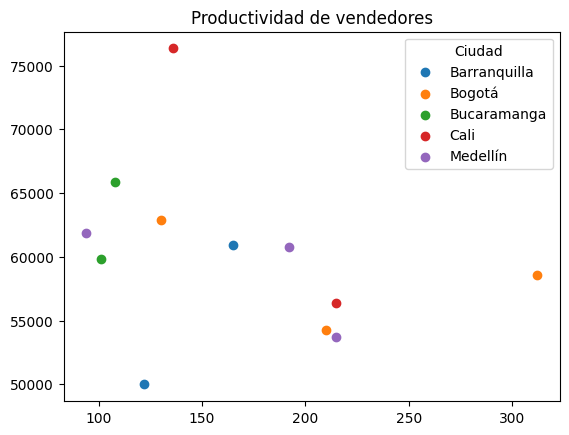

In [11]:
# Ejercicio 5
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

for ciudad, grupo in vend.groupby("ciudad"):
    plt.scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad)

plt.title("Productividad de vendedores")
plt.legend(title="Ciudad")

In [ ]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

Text(0.5, 0.98, 'Total por segmento (segundo semestre)')

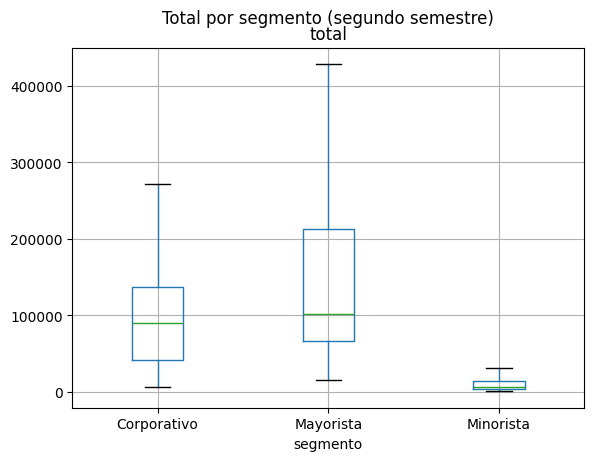

In [12]:
# Ejercicio 6
sem2 = df[df["mes"] >= 7]
sem2.boxplot(column="total", by="segmento", showfliers=False)
plt.suptitle("Total por segmento (segundo semestre)")

In [ ]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [13]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
top_productos.plot.barh(ax=axs[0, 0], title="Top 5 productos")

ing_mes_ciudad = df[df["ciudad"].isin(["Bogotá", "Medellín"])].pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum"
)
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Bogotá vs Medellín")

ing_canal = df.groupby("canal")["total"].sum()
ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", title="Ingresos por canal")

tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, title="Categorías por segmento (%)")

vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()
for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad)
axs[1, 1].set_title("Productividad vendedores")
axs[1, 1].legend(title="Ciudad")

sem2 = df[df["mes"] >= 7]
sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set_title("Ventas por segmento (S2)")

fig.suptitle("Dashboard de ventas 2025")
plt.tight_layout()

Overwriting figura_base.py


In [14]:
%run -i figura_base.py

In [ ]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [15]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
top_productos.plot.barh(ax=axs[0, 0], title="Top 5 productos")

ing_mes_ciudad = df[df["ciudad"].isin(["Bogotá", "Medellín"])].pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum"
)
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Bogotá vs Medellín")

ing_canal = df.groupby("canal")["total"].sum()
ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", title="Ingresos por canal")

tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, title="Categorías por segmento (%)")

vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).r

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [16]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La Gerencia y área comercial de la cadena de papelerías para revisar los resultados de 2025 por producto, ciudades principales, canales, categorías por segmento, productividad de vendedores y ventas del segundo semestre.

PALETA Y TIPOGRAFÍA: Fondo blanco limpio, letra clara sin adornos, títulos en negrita y etiquetas legibles. Paleta con azul oscuro y verde azulado como base, y naranja para resaltar datos clave.

TÍTULOS: Que cada gráfico tenga un título corto que muestre el resultado principal (por ejemplo: que Cuaderno lidera el top 5, que Bogotá supera a Medellín en el año o que el canal Telefónico concentra más de la mitad de las ventas)

EJES Y NÚMEROS: Usar separador de miles en los valores monetarios, mostrar todos los meses del 1 al 12 en el gráfico de líneas y poner nombres claros en los ejes.

LIMPIEZA VISUAL: Quitar bordes superior y derecho (top y right), poner cuadrícula suave de fondo y mostrar el valor de cada barra en el gráfico horizontal.
"""

print(prompt_v1)    # cópialo en la IA, junto con tu código y las reglas


PÚBLICO Y OBJETIVO: La Gerencia y área comercial de la cadena de papelerías para revisar los resultados de 2025 por producto, ciudades principales, canales, categorías por segmento, productividad de vendedores y ventas del segundo semestre.

PALETA Y TIPOGRAFÍA: Fondo blanco limpio, letra clara sin adornos, títulos en negrita y etiquetas legibles. Paleta con azul oscuro y verde azulado como base, y naranja para resaltar datos clave.

TÍTULOS: Que cada gráfico tenga un título corto que muestre el resultado principal (por ejemplo: que Cuaderno lidera el top 5, que Bogotá supera a Medellín en el año o que el canal Telefónico concentra más de la mitad de las ventas)

EJES Y NÚMEROS: Usar separador de miles en los valores monetarios, mostrar todos los meses del 1 al 12 en el gráfico de líneas y poner nombres claros en los ejes.

LIMPIEZA VISUAL: Quitar bordes superior y derecho (top y right), poner cuadrícula suave de fondo y mostrar el valor de cada barra en el gráfico horizontal.



In [17]:
%%writefile figura_v1.py
# Pega aquí SOLO el código que te devolvió la IA (sin las líneas ```)
fig, axs = plt.subplots(2, 3, figsize=(20, 11))
fig.patch.set_facecolor("white")

azul = "#1B4965"
teal = "#2A9D8F"
naranja = "#E07A5F"
colores_cat = ["#1D3557", "#457B9D", "#2A9D8F", "#E9C46A", "#E76F51"]

# (0, 0) Top 5 productos
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
col_barras = [naranja if prod == "Cuaderno" else azul for prod in top_productos.index]
barras = axs[0, 0].barh(top_productos.index, top_productos.values, color=col_barras)
axs[0, 0].invert_yaxis()
axs[0, 0].set_title("Cuaderno lidera el top 5 de ingresos", fontsize=11, fontweight="bold", loc="left")
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].set_xlim(0, top_productos.max() * 1.18)
axs[0, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axs[0, 0].grid(axis="x", linestyle="--", alpha=0.35)
axs[0, 0].spines["top"].set_visible(False)
axs[0, 0].spines["right"].set_visible(False)
for b in barras:
    w = b.get_width()
    axs[0, 0].text(w * 1.01, b.get_y() + b.get_height() / 2, f"${w:,.0f}", va="center", ha="left", fontsize=8.5)

# (0, 1) Bogotá vs Medellín mes a mes
ing_mes_ciudad = df[df["ciudad"].isin(["Bogotá", "Medellín"])].pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum"
)
col_ciu = {"Bogotá": azul, "Medellín": naranja}
for c in ing_mes_ciudad.columns:
    axs[0, 1].plot(ing_mes_ciudad.index, ing_mes_ciudad[c], marker="o", linewidth=2, color=col_ciu[c], label=c)
axs[0, 1].set_title("Bogotá acumula más ingresos anuales que Medellín", fontsize=11, fontweight="bold", loc="left")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y:,.0f}"))
axs[0, 1].grid(True, linestyle="--", alpha=0.35)
axs[0, 1].spines["top"].set_visible(False)
axs[0, 1].spines["right"].set_visible(False)
axs[0, 1].legend(frameon=False, title="Ciudad")

# (0, 2) Participación por canal
ing_canal = df.groupby("canal")["total"].sum()
axs[0, 2].pie(
    ing_canal.values,
    labels=ing_canal.index,
    autopct="%.1f%%",
    startangle=90,
    colors=[naranja, azul, teal],
    wedgeprops={"edgecolor": "white", "linewidth": 1.2}
)
axs[0, 2].set_title("El canal Telefónico concentra más de la mitad de las ventas", fontsize=11, fontweight="bold", loc="left")

# (1, 0) Segmento vs categoría (%)
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, color=colores_cat, width=0.58)
axs[1, 0].set_title("Distribución porcentual de categorías por segmento", fontsize=11, fontweight="bold", loc="left")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].set_ylim(0, 100)
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].grid(axis="y", linestyle="--", alpha=0.35)
axs[1, 0].spines["top"].set_visible(False)
axs[1, 0].spines["right"].set_visible(False)
axs[1, 0].legend(title="Categoría", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

# (1, 1) Productividad de vendedores
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()
pal_disp = [azul, naranja, teal, "#6D597A", "#E9C46A", "#457B9D"]
for i, (ciudad, grupo) in enumerate(vend.groupby("ciudad")):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad, color=pal_disp[i % len(pal_disp)], s=70)
axs[1, 1].set_title("Cantidad de ventas vs. ticket promedio por vendedor", fontsize=11, fontweight="bold", loc="left")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y:,.0f}"))
axs[1, 1].grid(True, linestyle="--", alpha=0.35)
axs[1, 1].spines["top"].set_visible(False)
axs[1, 1].spines["right"].set_visible(False)
axs[1, 1].legend(frameon=False, title="Ciudad", ncol=2, fontsize=8.5)

# (1, 2) Boxplot por segmento (segundo semestre, sin atípicos)
sem2 = df[df["mes"] >= 7]
segs = sorted(sem2["segmento"].unique())
datos_b = [sem2.loc[sem2["segmento"] == s, "total"] for s in segs]
bp = axs[1, 2].boxplot(datos_b, labels=segs, showfliers=False, patch_artist=True)
for box, c in zip(bp["boxes"], [azul, teal, naranja]):
    box.set_facecolor(c)
    box.set_alpha(0.75)
for med in bp["medians"]:
    med.set_color("black")
    med.set_linewidth(2)
axs[1, 2].set_title("Valor de ventas por segmento en el segundo semestre", fontsize=11, fontweight="bold", loc="left")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total ($)")
axs[1, 2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y:,.0f}"))
axs[1, 2].grid(axis="y", linestyle="--", alpha=0.35)
axs[1, 2].spines["top"].set_visible(False)
axs[1, 2].spines["right"].set_visible(False)

fig.suptitle("Dashboard de ventas 2025 (v1)", fontsize=15, fontweight="bold")
plt.tight_layout()

Overwriting figura_v1.py


<string>:89: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


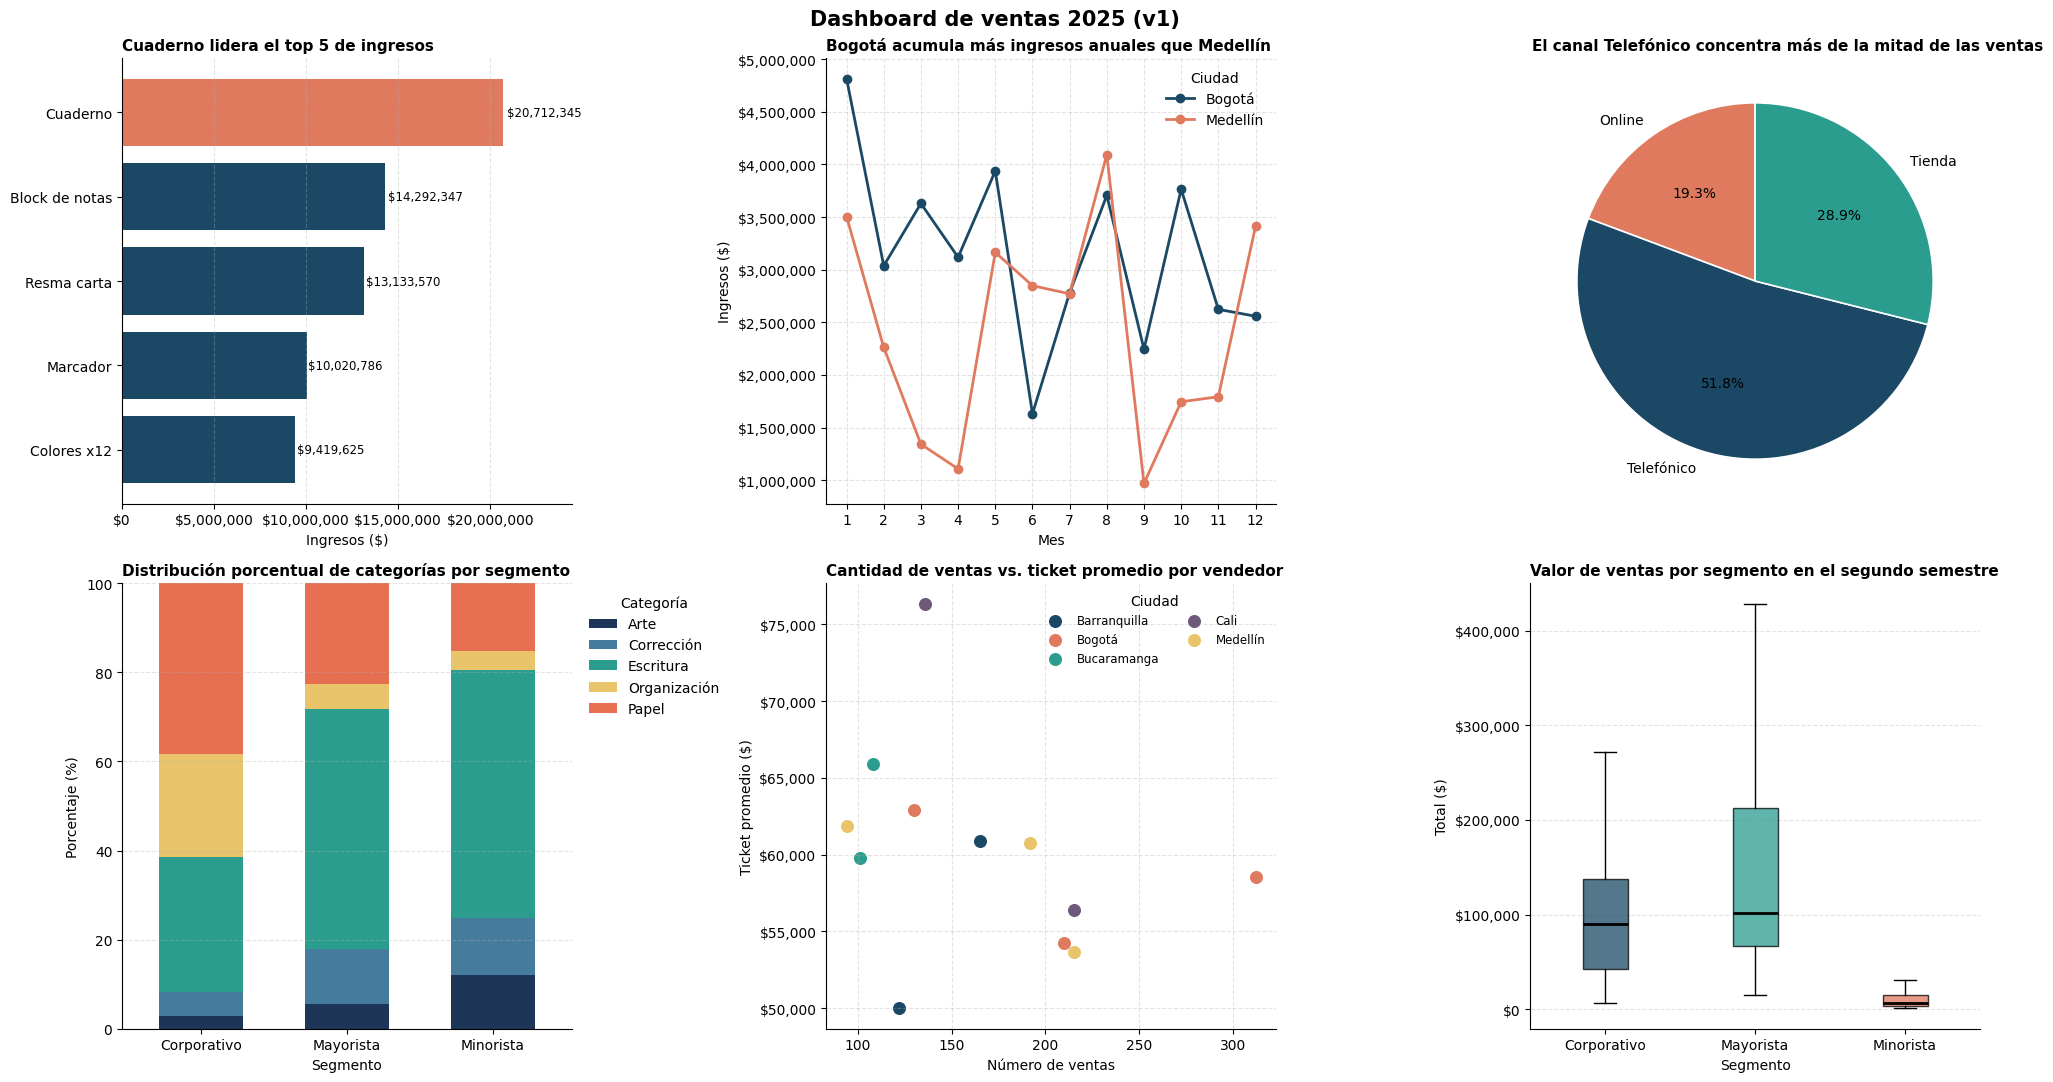

In [18]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [19]:
prompt_v2 = prompt_v1 + """

AJUSTES:
1. Cambia el gráfico de pie de canales a un gráfico de dona y muestra el ingreso total ($118.7M) en el centro.
2. Escribe en el gráfico de líneas el mes y valor máximo de Bogotá y de Medellín, y muestra los ejes de montos grandes en millones (ej. $20.0M)..
"""

print(prompt_v2)


PÚBLICO Y OBJETIVO: La Gerencia y área comercial de la cadena de papelerías para revisar los resultados de 2025 por producto, ciudades principales, canales, categorías por segmento, productividad de vendedores y ventas del segundo semestre.

PALETA Y TIPOGRAFÍA: Fondo blanco limpio, letra clara sin adornos, títulos en negrita y etiquetas legibles. Paleta con azul oscuro y verde azulado como base, y naranja para resaltar datos clave.

TÍTULOS: Que cada gráfico tenga un título corto que muestre el resultado principal (por ejemplo: que Cuaderno lidera el top 5, que Bogotá supera a Medellín en el año o que el canal Telefónico concentra más de la mitad de las ventas)

EJES Y NÚMEROS: Usar separador de miles en los valores monetarios, mostrar todos los meses del 1 al 12 en el gráfico de líneas y poner nombres claros en los ejes.

LIMPIEZA VISUAL: Quitar bordes superior y derecho (top y right), poner cuadrícula suave de fondo y mostrar el valor de cada barra en el gráfico horizontal.


AJUST

In [20]:
%%writefile figura_v2.py
# Pega aquí el código que te devolvió la IA para la versión 2
fig, axs = plt.subplots(2, 3, figsize=(21, 11.5))
fig.patch.set_facecolor("white")

azul = "#1B4965"
teal = "#2A9D8F"
naranja = "#E07A5F"
colores_cat = ["#1D3557", "#457B9D", "#2A9D8F", "#E9C46A", "#E76F51"]

def a_millones(x, _):
    return f"${x / 1e6:.1f}M"

# (0, 0) Top 5 productos
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
col_barras = [naranja if prod == "Cuaderno" else azul for prod in top_productos.index]
barras = axs[0, 0].barh(top_productos.index, top_productos.values, color=col_barras)
axs[0, 0].invert_yaxis()
axs[0, 0].set_title("Cuaderno lidera el top 5 de ingresos", fontsize=11, fontweight="bold", loc="left")
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].set_xlim(0, top_productos.max() * 1.18)
axs[0, 0].xaxis.set_major_formatter(plt.FuncFormatter(a_millones))
axs[0, 0].grid(axis="x", linestyle="--", alpha=0.35)
axs[0, 0].spines["top"].set_visible(False)
axs[0, 0].spines["right"].set_visible(False)
for b in barras:
    w = b.get_width()
    axs[0, 0].text(w * 1.01, b.get_y() + b.get_height() / 2, f"${w:,.0f}", va="center", ha="left", fontsize=8.5)

# (0, 1) Bogotá vs Medellín mes a mes + máximos
ing_mes_ciudad = df[df["ciudad"].isin(["Bogotá", "Medellín"])].pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum"
)
col_ciu = {"Bogotá": azul, "Medellín": naranja}
for c in ing_mes_ciudad.columns:
    serie = ing_mes_ciudad[c]
    axs[0, 1].plot(serie.index, serie.values, marker="o", linewidth=2.2, color=col_ciu[c], label=c)
    m_max = serie.idxmax()
    v_max = serie.max()
    axs[0, 1].annotate(
        f"Mes {int(m_max)}: ${v_max / 1e6:.1f}M",
        xy=(m_max, v_max),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        color=col_ciu[c]
    )
axs[0, 1].set_title("Bogotá acumula más ingresos anuales que Medellín", fontsize=11, fontweight="bold", loc="left")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].set_ylim(0, ing_mes_ciudad.values.max() * 1.18)
axs[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(a_millones))
axs[0, 1].grid(True, linestyle="--", alpha=0.35)
axs[0, 1].spines["top"].set_visible(False)
axs[0, 1].spines["right"].set_visible(False)
axs[0, 1].legend(frameon=False, title="Ciudad")

# (0, 2) Dona por canal con total en el centro
ing_canal = df.groupby("canal")["total"].sum()
axs[0, 2].pie(
    ing_canal.values,
    labels=ing_canal.index,
    autopct="%.1f%%",
    startangle=90,
    colors=[naranja, azul, teal],
    pctdistance=0.78,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 1.5}
)
axs[0, 2].text(0, 0, f"Total\n${ing_canal.sum() / 1e6:.1f}M", ha="center", va="center", fontsize=10, fontweight="bold", color=azul)
axs[0, 2].set_title("El canal Telefónico concentra más de la mitad de las ventas", fontsize=11, fontweight="bold", loc="left")

# (1, 0) Segmento vs categoría (%)
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, color=colores_cat, width=0.58)
axs[1, 0].set_title("Distribución porcentual de categorías por segmento", fontsize=11, fontweight="bold", loc="left")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].set_ylim(0, 100)
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].grid(axis="y", linestyle="--", alpha=0.35)
axs[1, 0].spines["top"].set_visible(False)
axs[1, 0].spines["right"].set_visible(False)
axs[1, 0].legend(title="Categoría", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)

# (1, 1) Productividad de vendedores
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()
pal_disp = [azul, naranja, teal, "#6D597A", "#E9C46A", "#457B9D"]
for i, (ciudad, grupo) in enumerate(vend.groupby("ciudad")):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], label=ciudad, color=pal_disp[i % len(pal_disp)], s=70)
axs[1, 1].set_title("Cantidad de ventas vs. ticket promedio por vendedor", fontsize=11, fontweight="bold", loc="left")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y:,.0f}"))
axs[1, 1].grid(True, linestyle="--", alpha=0.35)
axs[1, 1].spines["top"].set_visible(False)
axs[1, 1].spines["right"].set_visible(False)
axs[1, 1].legend(frameon=False, title="Ciudad", ncol=2, fontsize=8.5)

# (1, 2) Boxplot por segmento (segundo semestre, sin atípicos)
sem2 = df[df["mes"] >= 7]
segs = sorted(sem2["segmento"].unique())
datos_b = [sem2.loc[sem2["segmento"] == s, "total"] for s in segs]
bp = axs[1, 2].boxplot(datos_b, labels=segs, showfliers=False, patch_artist=True)
for box, c in zip(bp["boxes"], [azul, teal, naranja]):
    box.set_facecolor(c)
    box.set_alpha(0.75)
for med in bp["medians"]:
    med.set_color("black")
    med.set_linewidth(2)
axs[1, 2].set_title("Valor de ventas por segmento en el segundo semestre", fontsize=11, fontweight="bold", loc="left")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total ($)")
axs[1, 2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"${y:,.0f}"))
axs[1, 2].grid(axis="y", linestyle="--", alpha=0.35)
axs[1, 2].spines["top"].set_visible(False)
axs[1, 2].spines["right"].set_visible(False)

fig.suptitle("Dashboard de ventas 2025 (v2)", fontsize=15, fontweight="bold")
plt.tight_layout()

Overwriting figura_v2.py


<string>:108: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


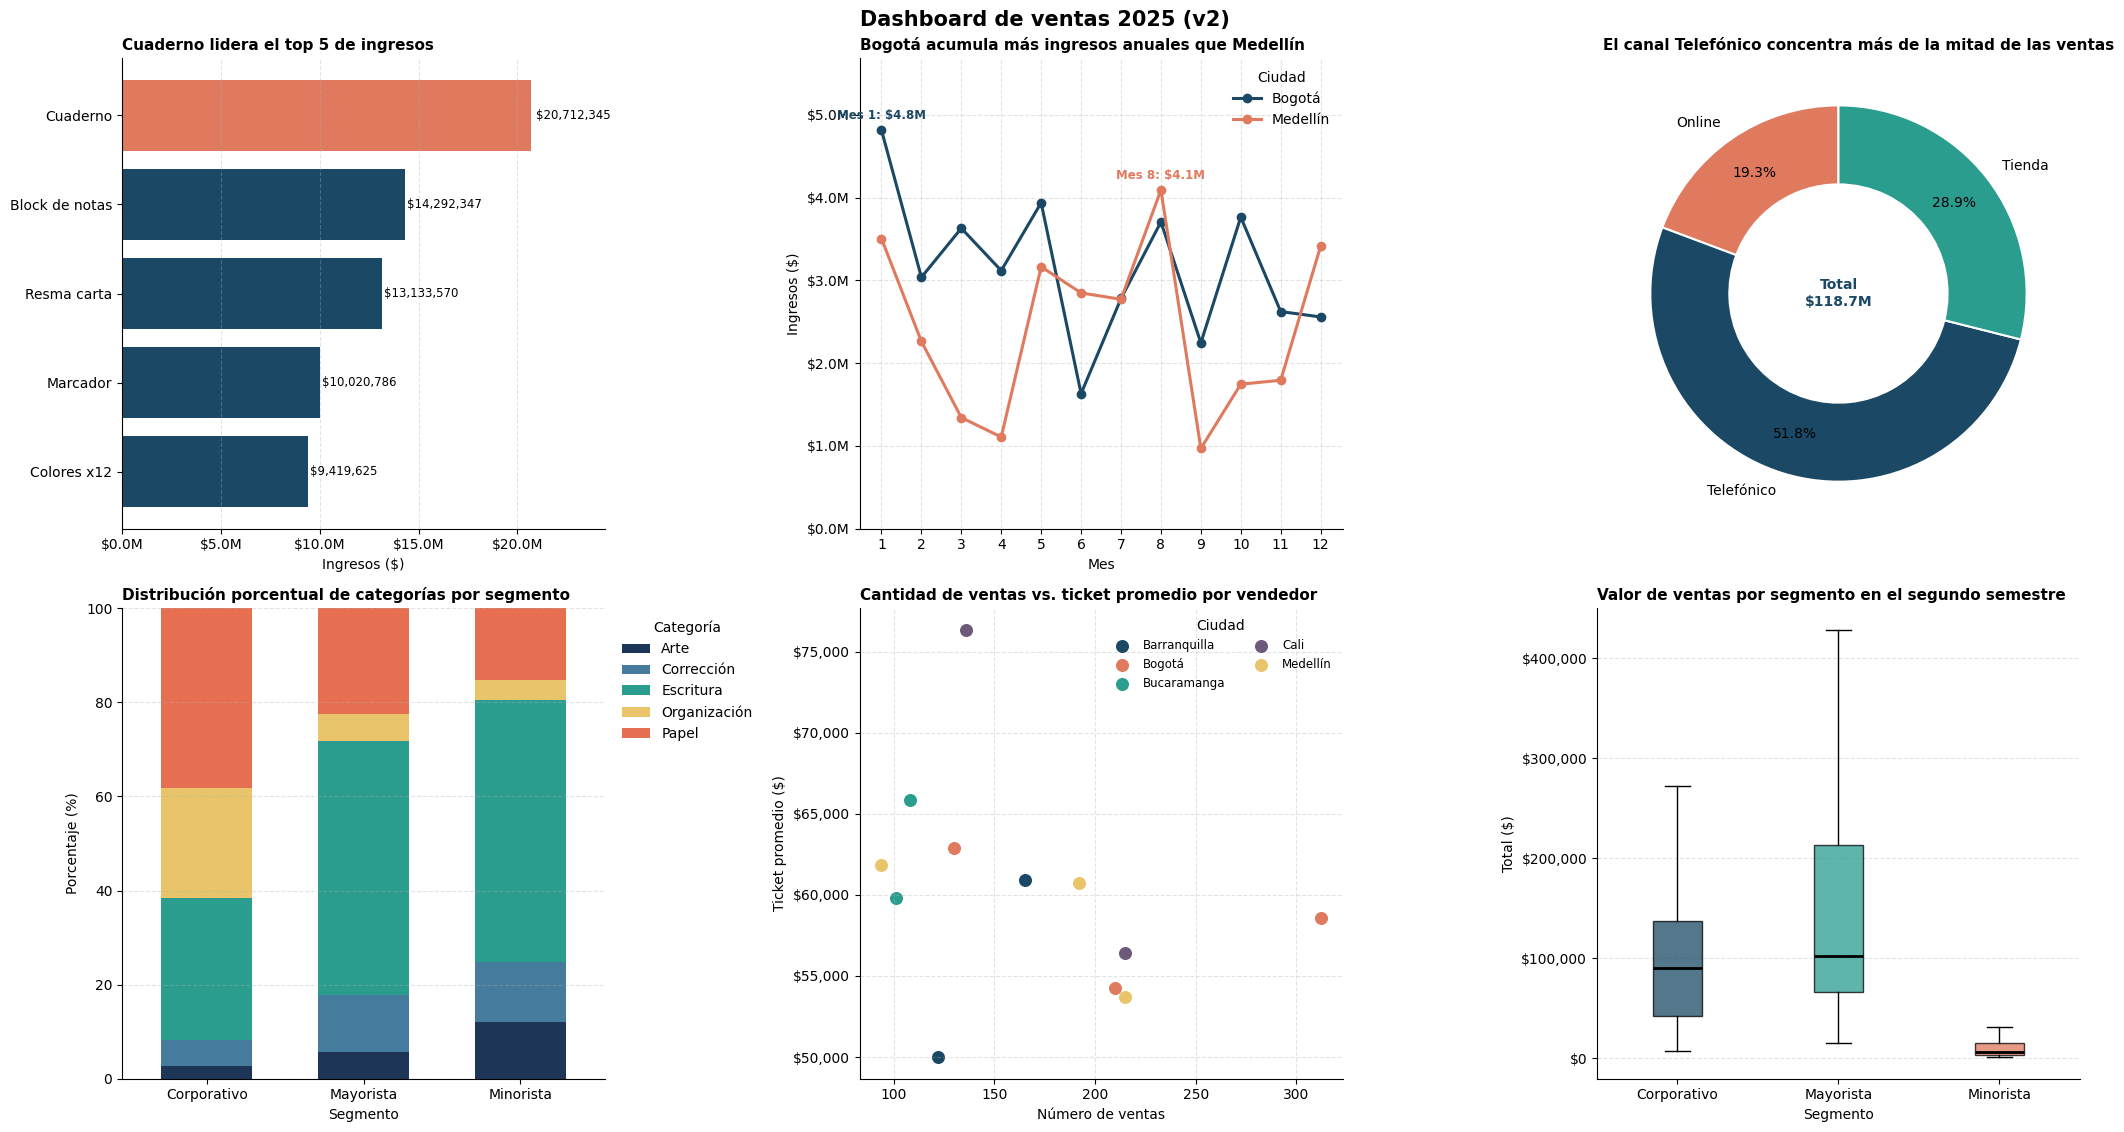

In [21]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [ ]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# print(prompt_v3)

In [ ]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [22]:
figura_elegida = "v2"      # cambia por "v1", "v2" o "v3"

hallazgos = [
    "El canal Telefónico aporta el 51.8 % ($61,450,716) de los $118,668,012 en ingresos totales de 2025.",
    "Cuaderno es el producto con más ingresos ($20,712,345), por encima de Block de notas ($14,292,347).",
    "Bogotá suma $37,847,614 en el año frente a $29,015,462 de Medellín, con picos en enero ($4,815,405) y agosto ($4,092,446).",
]

In [ ]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

<string>:108: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


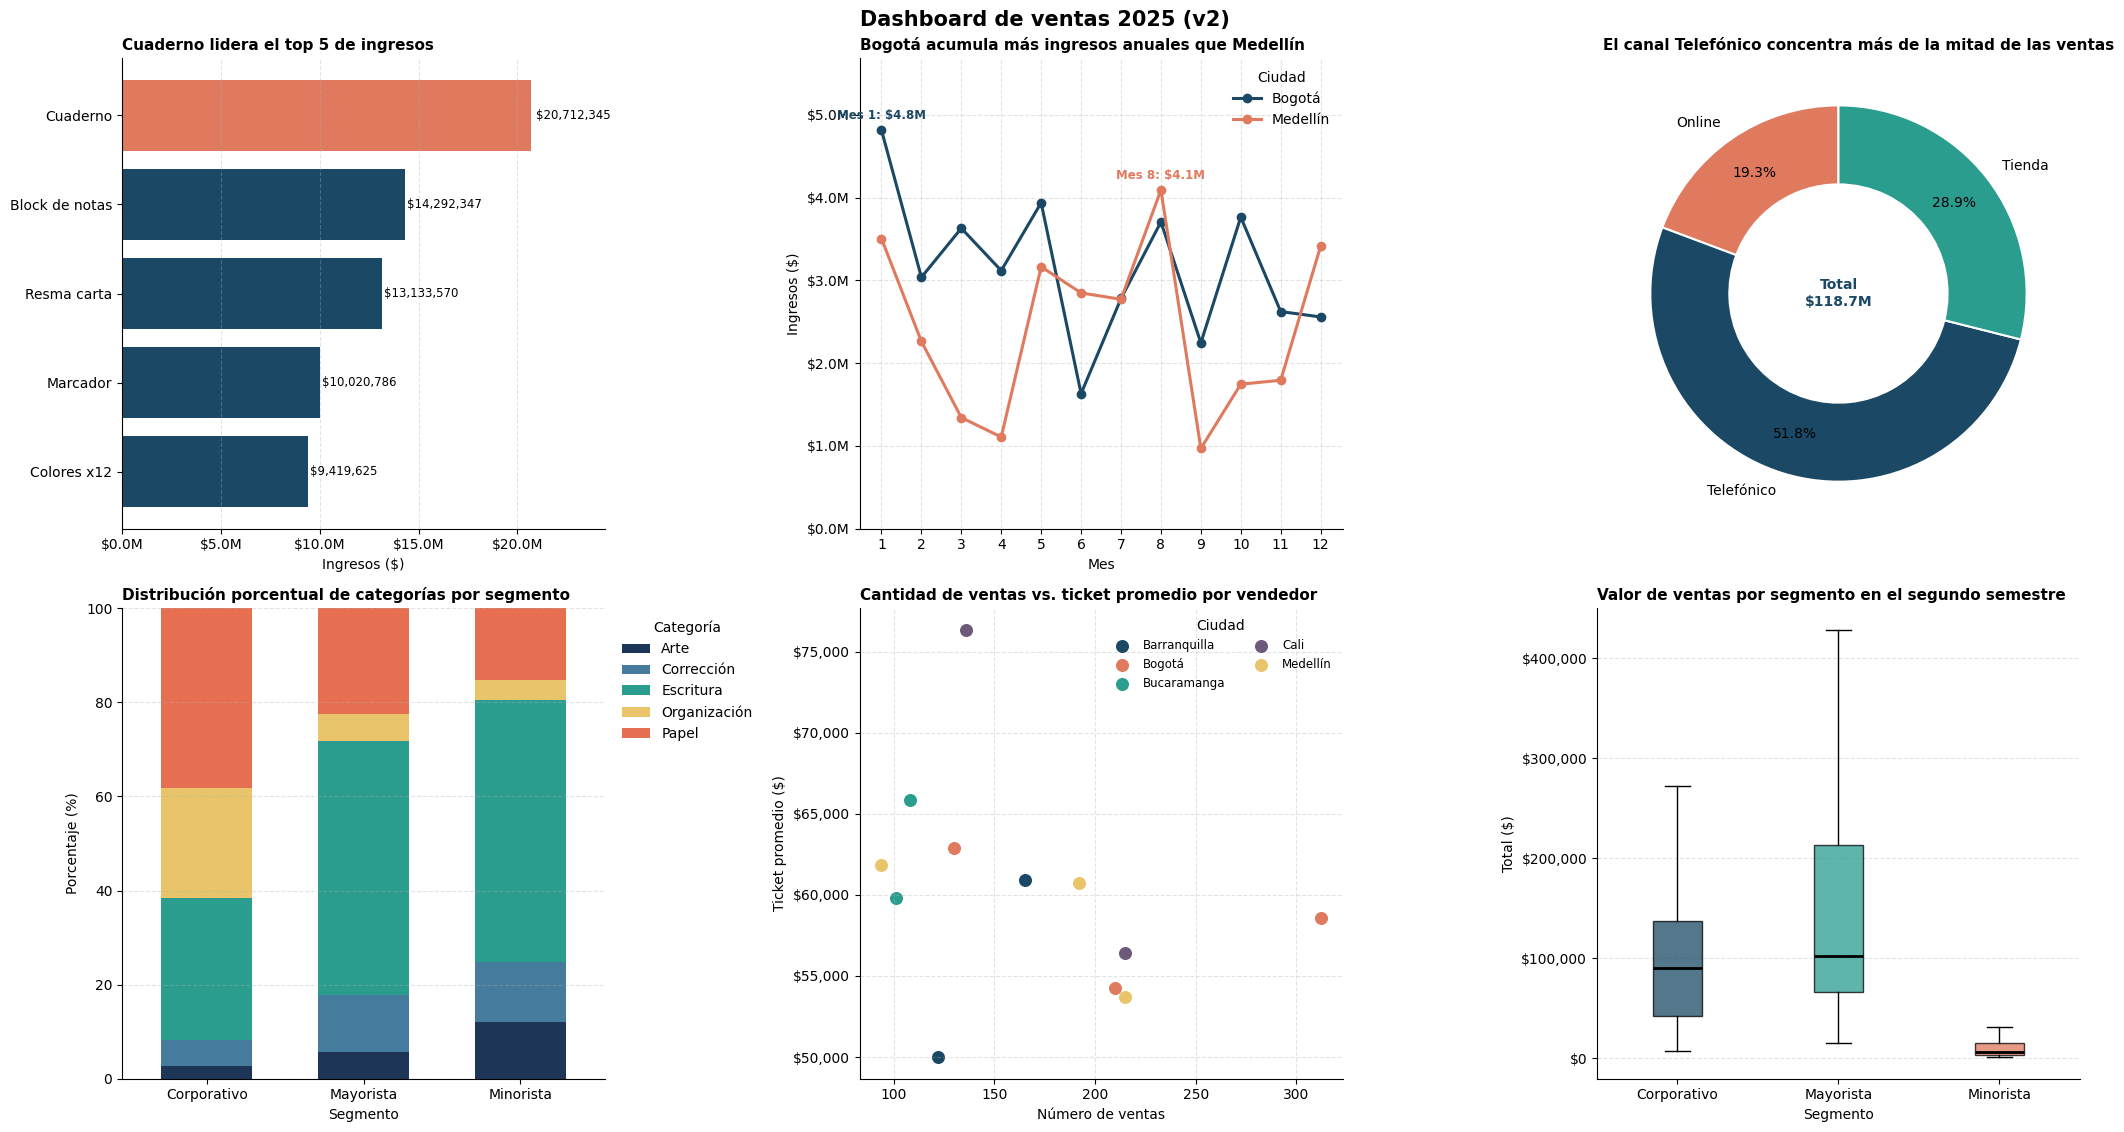

Hallazgos:
• El canal Telefónico aporta el 51.8 % ($61,450,716) de los $118,668,012 en ingresos totales de 2025.
• Cuaderno es el producto con más ingresos ($20,712,345), por encima de Block de notas ($14,292,347).
• Bogotá suma $37,847,614 en el año frente a $29,015,462 de Medellín, con picos en enero ($4,815,405) y agosto ($4,092,446).


In [23]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.